# Iris Flower Classification Using Machine Learning

## Project Objective
The objective of this project is to build a machine learning
classification model that predicts the species of an Iris flower
based on its physical measurements.

## Species
1. Iris Setosa
2. Iris Versicolor
3. Iris Virginica

In [5]:
from sklearn.datasets import load_iris

iris = load_iris()

print("Iris dataset loaded successfully!")
print("Number of samples:", len(iris.data))
print("Number of features:", len(iris.feature_names))
print("Flower species:", iris.target_names)

Iris dataset loaded successfully!
Number of samples: 150
Number of features: 4
Flower species: ['setosa' 'versicolor' 'virginica']


In [7]:
print("Feature names:", iris.feature_names)

print("\nFirst five flower measurements:")
print(iris.data[:5])

print("\nFirst five target values:")
print(iris.target[:5])

print("\nTarget names:")
print(iris.target_names)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

First five flower measurements:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

First five target values:
[0 0 0 0 0]

Target names:
['setosa' 'versicolor' 'virginica']


In [8]:
from sklearn.model_selection import train_test_split

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=200)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [10]:
y_pred = model.predict(X_test)

print("Predicted values:", y_pred)

print("Actual values:", y_test)


Predicted values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Actual values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


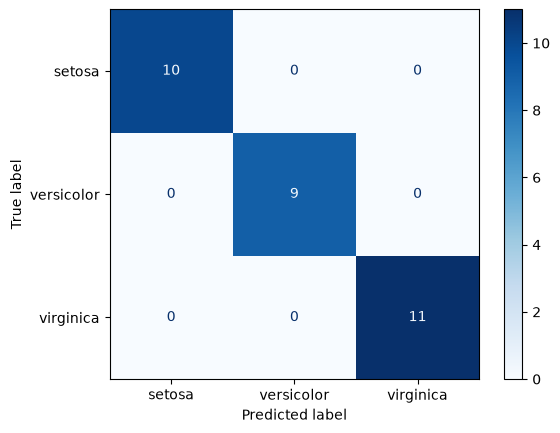

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot(cmap="Blues")
plt.show()

In [13]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)

print("Predicted flower:", iris.target_names[prediction[0]])

Predicted flower: setosa


In [14]:
print("Enter flower measurements:")

sepal_length = float(input("Sepal length: "))
sepal_width = float(input("Sepal width: "))
petal_length = float(input("Petal length: "))
petal_width = float(input("Petal width: "))

new_flower = [[
    sepal_length,
    sepal_width,
    petal_length,
    petal_width
]]

prediction = model.predict(new_flower)

print("\nPredicted flower species:",
      iris.target_names[prediction[0]])

Enter flower measurements:

Predicted flower species: setosa


In [15]:
probabilities = model.predict_proba(new_flower)

print("Prediction probabilities:")

for species, probability in zip(iris.target_names, probabilities[0]):
    print(species, ":", round(probability * 100, 2), "%")

Prediction probabilities:
setosa : 97.66 %
versicolor : 2.34 %
virginica : 0.0 %
